In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/graphcast_ifs_hamburg_t2m_precip.csv",
                 parse_dates=["init_time", "time"]
)

df.head()

,init_time,s3_prefix,time,t2,apcp,longitude,latitude
0,2024-04-01,GRAP_v100_IFS,2024-04-01 00:00:00,279.55682,0.000000,10.0,53.75
1,2024-04-01,GRAP_v100_IFS,2024-04-01 06:00:00,280.10970,0.000070,10.0,53.75
2,2024-04-01,GRAP_v100_IFS,2024-04-01 12:00:00,283.41177,0.003394,10.0,53.75
3,2024-04-01,GRAP_v100_IFS,2024-04-01 18:00:00,281.67920,0.008991,10.0,53.75
4,2024-04-01,GRAP_v100_IFS,2024-04-02 00:00:00,280.93520,0.002405,10.0,53.75


In [13]:
#Daten vereinheitlichen, Kelvin auf Celsius umrechnen

In [14]:
# Kelvin → Celsius
df["temperature_2m"] = df["t2"] - 273.15

# Forecast-Horizont rekonstruieren
df["lead_time_h"] = (
    df["time"] - df["init_time"]
).dt.total_seconds() / 3600

In [15]:
#Grundlagen und Vollständigkeit

In [16]:
print(f"Datensätze: {len(df):,}")

print("Forecasts von:",
      df["init_time"].min())

print("Forecasts bis:",
      df["init_time"].max())

Datensätze: 31,201
Forecasts von: 2024-04-01 00:00:00
Forecasts bis: 2026-11-18 00:00:00


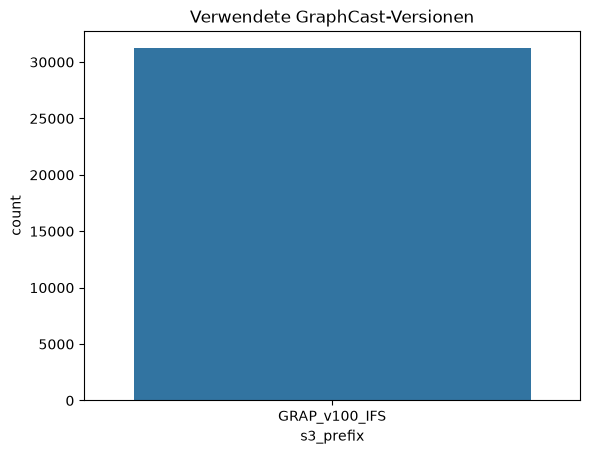

In [17]:
df["s3_prefix"].value_counts()

sns.countplot(
    data=df,
    x="s3_prefix"
)

plt.title("Verwendete GraphCast-Versionen")
plt.show()

In [18]:
forecast_sizes = (
    df.groupby("init_time")
      .size()
)

forecast_sizes.describe()

count    761.0
mean      41.0
std        0.0
min       41.0
25%       41.0
50%       41.0
75%       41.0
max       41.0
dtype: float64

In [19]:

expected_steps = 41

print(forecast_sizes[
    forecast_sizes != expected_steps
])

Series([], dtype: int64)


In [20]:
#wenn Vorhersage vorhanden, dann sind alle Schritte vorhanden. Es gibt also keine unvollständigen Vorhersagen.

In [21]:
#Fehlende Tage

In [22]:
with open(
    "../data/full_datasets/graphcast_missing_inits.txt"
) as f:
    missing = f.read().splitlines()

print(
    f"{len(missing)} Forecasts fehlen"
)

198 Forecasts fehlen


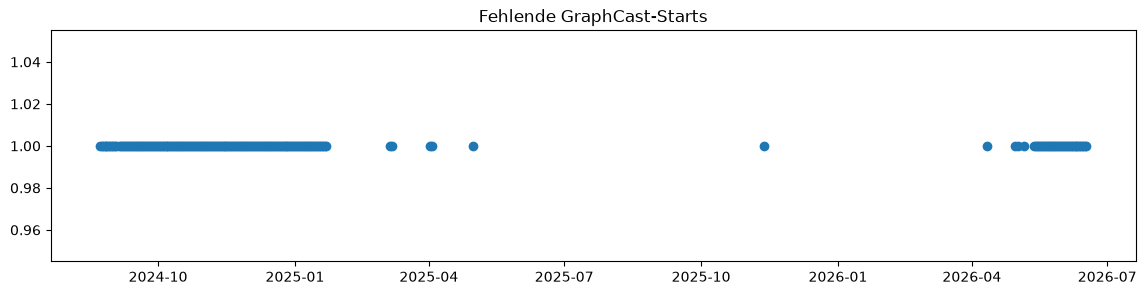

In [23]:
missing_dates = pd.to_datetime(missing)

plt.figure(figsize=(14,3))
plt.scatter(
    missing_dates,
    np.ones(len(missing_dates))
)

plt.title("Fehlende GraphCast-Starts")
plt.show()

In [24]:
#Nicht ausgefüllte Felder -> keine fehlenden Werte

In [25]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent":
        100 * df.isna().sum() / len(df)
})

display(missing)

,count,percent
init_time,0,0.0
s3_prefix,0,0.0
time,0,0.0
t2,0,0.0
apcp,0,0.0
longitude,0,0.0
latitude,0,0.0
temperature_2m,0,0.0
lead_time_h,0,0.0


In [26]:
#Temperaturverteilung

In [27]:
df["temperature_2m"].describe()

count    3.120100e+04
mean     4.824687e+34
std      6.918604e+35
min     -1.149010e+01
25%      6.194970e+00
50%      1.200045e+01
75%      1.658624e+01
max      9.969210e+36
Name: temperature_2m, dtype: float64

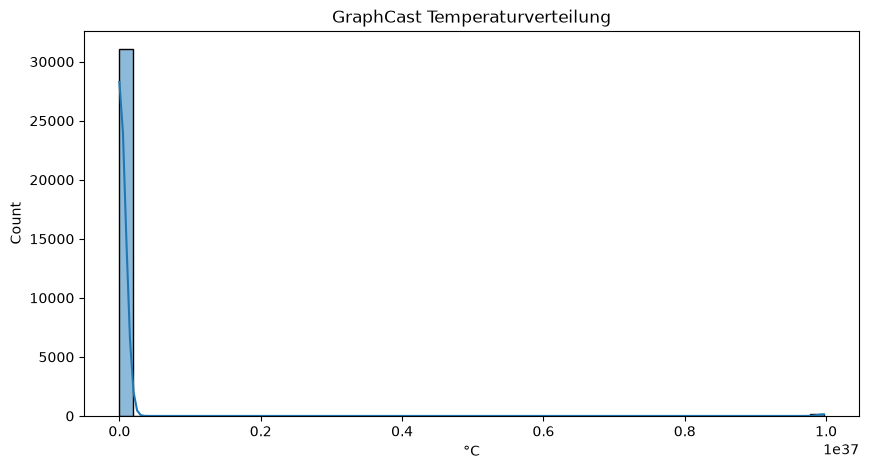

In [28]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=50,
    kde=True
)

plt.xlabel("°C")
plt.title("GraphCast Temperaturverteilung")
plt.show()

In [29]:
# Sehr große Werte suchen
outliers = df[df["t2"] > 1000]

print(f"Anzahl verdächtiger Datensätze: {len(outliers)}")

outliers.head()

Anzahl verdächtiger Datensätze: 151


,init_time,s3_prefix,time,t2,apcp,longitude,latitude,temperature_2m,lead_time_h
24887,2026-06-18,GRAP_v100_IFS,2026-06-18,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24928,2026-06-19,GRAP_v100_IFS,2026-06-19,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24969,2026-06-20,GRAP_v100_IFS,2026-06-20,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
25010,2026-06-21,GRAP_v100_IFS,2026-06-21,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
25051,2026-06-22,GRAP_v100_IFS,2026-06-22,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0


In [31]:
# Sehr große Werte suchen
outliers = df[df["t2"] < 150]

print(f"Anzahl verdächtiger Datensätze: {len(outliers)}")

outliers.head()

Anzahl verdächtiger Datensätze: 0


,init_time,s3_prefix,time,t2,apcp,longitude,latitude,temperature_2m,lead_time_h


In [30]:
# Sehr große Werte suchen
outliers = df[df["apcp"] > 1000]

print(f"Anzahl verdächtiger Datensätze: {len(outliers)}")

outliers.head()

Anzahl verdächtiger Datensätze: 302


,init_time,s3_prefix,time,t2,apcp,longitude,latitude,temperature_2m,lead_time_h
24887,2026-06-18,GRAP_v100_IFS,2026-06-18 00:00:00,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24888,2026-06-18,GRAP_v100_IFS,2026-06-18 06:00:00,2.912903e+02,9.969210e+36,10.0,53.75,1.814030e+01,6.0
24928,2026-06-19,GRAP_v100_IFS,2026-06-19 00:00:00,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
24929,2026-06-19,GRAP_v100_IFS,2026-06-19 06:00:00,2.933772e+02,9.969210e+36,10.0,53.75,2.022717e+01,6.0
24969,2026-06-20,GRAP_v100_IFS,2026-06-20 00:00:00,9.969210e+36,9.969210e+36,10.0,53.75,9.969210e+36,0.0
